In [2]:
from pathlib import Path
import re
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("../LogisticRegression_SpamOpinion/Datos/deceptive-opinion.csv")
df = pd.read_csv(DATA)

df.shape
df.head(3)

,deceptive,hotel,polarity,source,text
0,truthful,conrad,positive,TripAdvisor,We stayed for a one night getaway with family ...
1,truthful,hyatt,positive,TripAdvisor,Triple A rate with upgrade to view room was le...
2,truthful,hyatt,positive,TripAdvisor,This comes a little late as I'm finally catchi...


In [3]:
variable_map = pd.DataFrame({
    "column": df.columns,
    "dtype": df.dtypes.astype(str).values,
    "n_unique": [df[c].nunique() for c in df.columns],
    "n_missing": df.isna().sum().values,
    "role": ["target", "context", "second label", "metadata, do not use as a feature", "input text"],
})
variable_map

,column,dtype,n_unique,n_missing,role
0,deceptive,str,2,0,target
1,hotel,str,20,0,context
2,polarity,str,2,0,second label
3,source,str,3,0,"metadata, do not use as a feature"
4,text,str,1596,0,input text


In [4]:
counts = pd.crosstab(df["deceptive"], df["polarity"], margins=True)
counts

polarity,negative,positive,All
deceptive,,,
deceptive,400,400,800
truthful,400,400,800
All,800,800,1600


## Words shared by both classes (deceptive and truthful)

In [5]:
STOP = set("""
a an the and or but if in on of for to from with at by as is are was were be
been being it this that these those i you he she we they me my our your their
not no nor so very just about into over after before than then also
hotel hotels room rooms chicago stay stayed
""".split())

def tokens(text):
    words = re.findall(r"[a-z]+", str(text).lower())
    return {w for w in words if len(w) > 2 and w not in STOP}

def document_frequency(texts):
    counts = Counter()
    for text in texts:
        counts.update(tokens(text))
    return counts

dec = document_frequency(df.loc[df["deceptive"] == "deceptive", "text"])
tru = document_frequency(df.loc[df["deceptive"] == "truthful", "text"])

MIN_DOCS = 15
in_both = sorted(w for w in set(dec) & set(tru) if dec[w] >= MIN_DOCS and tru[w] >= MIN_DOCS)
only_deceptive = sorted(w for w in dec if dec[w] >= MIN_DOCS and tru[w] < MIN_DOCS)
only_truthful = sorted(w for w in tru if tru[w] >= MIN_DOCS and dec[w] < MIN_DOCS)

print(len(in_both), "words in both classes")
print(len(only_deceptive), "mostly deceptive:", only_deceptive[:25])
print(len(only_truthful), "mostly truthful:", only_truthful[:25])

584 words in both classes
134 mostly deceptive: ['accommodations', 'affinia', 'amount', 'anniversary', 'apparently', 'arriving', 'atmosphere', 'attention', 'awful', 'barely', 'beautifully', 'booking', 'chance', 'changed', 'children', 'cigarette', 'classy', 'cleaning', 'cleanliness', 'comfort', 'complained', 'computer', 'considering', 'conveniently', 'counter']
173 mostly truthful: ['additional', 'airport', 'anywhere', 'appointed', 'ate', 'attached', 'attentive', 'ave', 'avenue', 'awesome', 'bars', 'based', 'bath', 'bathrooms', 'beat', 'bedroom', 'bell', 'below', 'between', 'block', 'blocks', 'bottle', 'boutique', 'broken', 'buffet']


In [7]:
def rate_diff(sub):
    dec = document_frequency(sub.loc[sub["deceptive"] == "deceptive", "text"])
    tru = document_frequency(sub.loc[sub["deceptive"] == "truthful", "text"])
    n = 400
    rows = []
    for word in set(dec) | set(tru):
        if dec[word] + tru[word] < 20:
            continue
        rows.append({
            "word": word,
            "fake": dec[word] / n,
            "real": tru[word] / n,
            "diff": dec[word] / n - tru[word] / n,
        })
    return pd.DataFrame(rows).set_index("word")

pos = rate_diff(df[df["polarity"] == "positive"])
neg = rate_diff(df[df["polarity"] == "negative"])
both = pos.join(neg, lsuffix="_pos", rsuffix="_neg")

same_way = both[(both["diff_pos"] * both["diff_neg"]) > 0].copy()
same_way["gap"] = same_way[["diff_pos", "diff_neg"]].abs().min(axis=1)
same_way = same_way.sort_values("gap", ascending=False)

show = same_way.head(24)[[
    "fake_pos", "real_pos", "fake_neg", "real_neg", "diff_pos", "diff_neg"
]].round(2)
show

,fake_pos,real_pos,fake_neg,real_neg,diff_pos,diff_neg
word,,,,,,
location,0.20,0.48,0.10,0.29,-0.28,-0.19
great,0.42,0.57,0.12,0.26,-0.16,-0.13
experience,0.20,0.08,0.28,0.15,0.12,0.13
floor,0.03,0.19,0.10,0.20,-0.16,-0.11
small,0.02,0.13,0.10,0.20,-0.11,-0.10
luxury,0.11,0.01,0.13,0.01,0.10,0.12
staying,0.17,0.07,0.23,0.13,0.10,0.10
recommend,0.28,0.18,0.16,0.08,0.09,0.08
food,0.16,0.09,0.16,0.08,0.08,0.08


## Characteristics

Fake reviews usually focus on story, and some praise words, in the other side real reviews are more informative and describe places and objects.

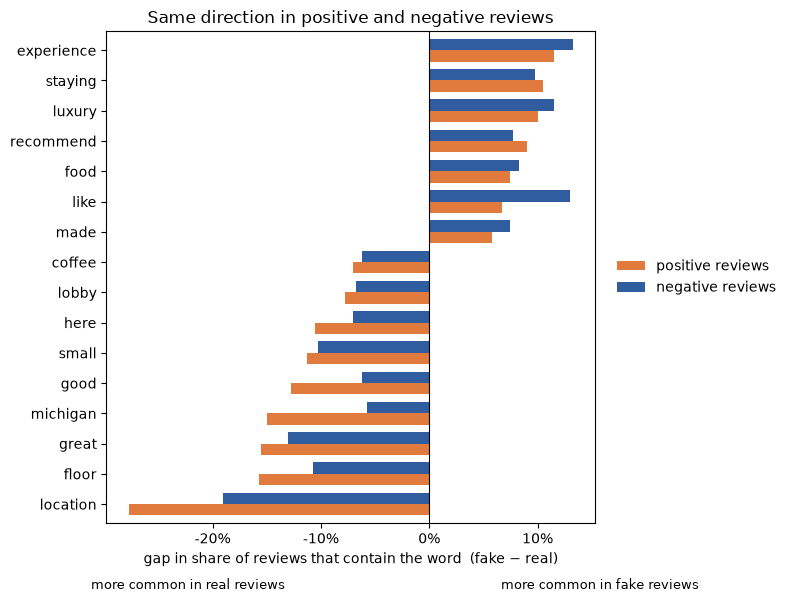

In [10]:
top = same_way.head(16).sort_values("diff_pos")

plot_df = top[["diff_pos", "diff_neg"]].rename(columns={
    "diff_pos": "positive reviews",
    "diff_neg": "negative reviews",
})

fig, ax = plt.subplots(figsize=(8, 6))
plot_df.plot.barh(ax=ax, color=["#e07a3d", "#2f5d9f"], width=0.75)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("gap in share of reviews that contain the word  (fake − real)")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
ax.set_title("Same direction in positive and negative reviews")
fig.text(0.12, 0.01, "more common in real reviews", ha="left", fontsize=9)
fig.text(0.88, 0.01, "more common in fake reviews", ha="right", fontsize=9)
fig.tight_layout()
fig.subplots_adjust(bottom=0.12, right=0.75)
plt.show()

39 words only in fake reviews
85 words only in real reviews


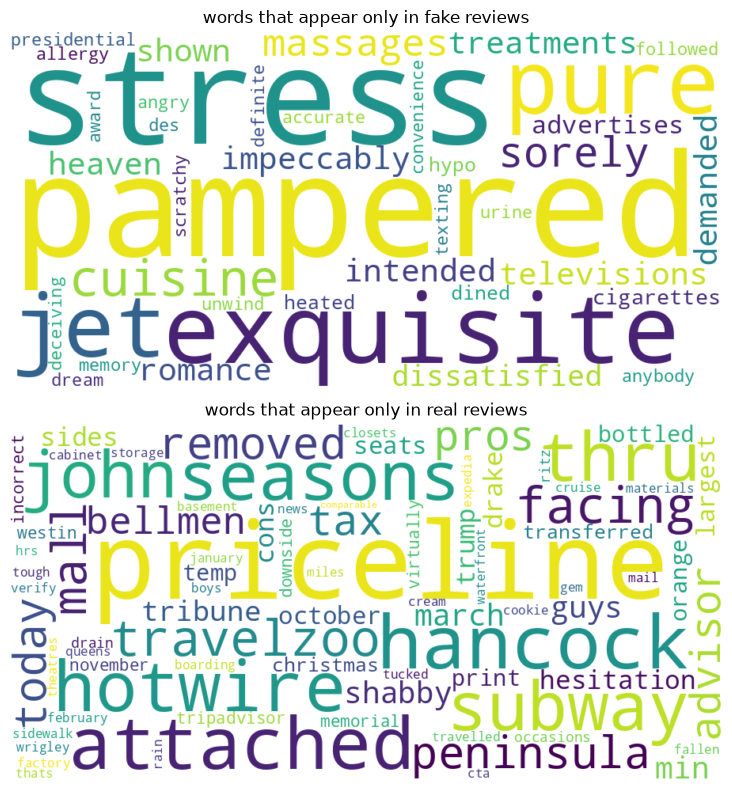

In [13]:
from wordcloud import WordCloud

def draw_cloud(counts, title, ax):
    cloud = WordCloud(
        width=900,
        height=450,
        background_color="white",
        max_words=80,
        random_state=0,
        colormap="viridis",
    ).generate_from_frequencies(counts)
    ax.imshow(cloud, interpolation="bilinear")
    ax.set_title(title)
    ax.axis("off")

only_fake = {word: n for word, n in dec.items() if word not in tru and n >= 5}
only_real = {word: n for word, n in tru.items() if word not in dec and n >= 5}

print(len(only_fake), "words only in fake reviews")
print(len(only_real), "words only in real reviews")

fig, axes = plt.subplots(2, 1, figsize=(10, 8))
draw_cloud(only_fake, "words that appear only in fake reviews", axes[0])
draw_cloud(only_real, "words that appear only in real reviews", axes[1])
fig.tight_layout()
plt.show()

## Bag of words and model training

In [15]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer(
    lowercase=True,
    token_pattern=r"[a-z]{3,}",
    stop_words=list(STOP),
    min_df=5,
)
X = vectorizer.fit_transform(df["text"])
words = vectorizer.get_feature_names_out()

bow = pd.DataFrame(X.toarray(), columns=words)
bow.insert(0, "deceptive", df["deceptive"].values)

print(bow.shape)
print("shortest word:", min(words, key=len))

(1600, 2605)
shortest word: aaa


In [18]:
# fake_counts = bow.loc[bow["deceptive"] == "deceptive", words].sum()
# real_counts = bow.loc[bow["deceptive"] == "truthful", words].sum()

# fig, axes = plt.subplots(2, 1, figsize=(10, 8))
# draw_cloud(fake_counts.to_dict(), "fake reviews, bag of words", axes[0])
# draw_cloud(real_counts.to_dict(), "real reviews, bag of words", axes[1])
# fig.tight_layout()
# plt.show()